# MATH 546 Capstone Stage 1

In [21]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf, adfuller, kpss

from capstone_support.capstone_data import load_dataset, chronological_split

H = 7
MIN_HISTORY = 42
SEED = 546
RIDGE_GRID = (1.0, 10.0, 100.0)
ASSETS = Path('capstone_stage1_assets')
ASSETS.mkdir(exist_ok=True)


def score(actual, pred):
    err = np.asarray(actual, float) - np.asarray(pred, float)
    return {'MAE': float(np.mean(np.abs(err))),
            'RMSE': float(np.sqrt(np.mean(err ** 2))),
            'WAPE_pct': float(100 * np.sum(np.abs(err)) / np.sum(np.abs(actual))),
            'bias': float(np.mean(-err))}


def weekly_origins(start_idx: int, end_idx: int):
    """First origin is day before block; score only complete non-overlapping H-day blocks."""
    return list(range(start_idx - 1, end_idx - H, H))

In [22]:
np.random.seed(SEED)

df = load_dataset('bike')
train, validation, test = chronological_split(df)
y = df['cnt'].to_numpy(float)
n = len(df)
n_train, n_val = len(train), len(validation)
test_start = n_train + n_val
assert n == 731 and n_train == 438 and n_val == 146 and len(test) == 147
assert df.index.freq is None or df.index.freq == 'D'
assert df.index.equals(pd.date_range(df.index[0], df.index[-1], freq='D', name=df.index.name))
assert not df['cnt'].isna().any()
# Future observed weather is explicitly excluded from ALL modeling inputs.
forbidden = {'temp', 'atemp', 'hum', 'windspeed', 'weathersit', 'casual', 'registered'}
source_used_features = {'cnt', 'holiday', 'workingday'}
assert not (source_used_features & forbidden)

print('Observations:', n, '| train:', n_train, '| validation:', n_val, '| test:', len(test))
print('Period:', df.index.min().date(), 'to', df.index.max().date())
print('Columns:', ', '.join(df.columns))

Observations: 731 | train: 438 | validation: 146 | test: 147
Period: 2011-01-01 to 2012-12-31
Columns: season, yr, mnth, holiday, weekday, workingday, weathersit, temp, atemp, hum, windspeed, cnt


## Diagnostics

In [23]:
# Training-only diagnostics; both ADF/KPSS nulls explained in the report.
diagnostics={}
for label, yy in [('level',train.cnt.to_numpy(float)),
                  ('weekly_difference',(train.cnt-train.cnt.shift(7)).dropna().to_numpy(float))]:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        adf_result=adfuller(yy,autolag='AIC')
        kpss_result=kpss(yy,regression='c',nlags='auto')
    diagnostics[label]={'ADF_stat':float(adf_result[0]),'ADF_p':float(adf_result[1]),
                        'KPSS_stat':float(kpss_result[0]),'KPSS_p':float(kpss_result[1])}
diagnostics['ACF_lag7']=float(acf(train.cnt,nlags=14,fft=True)[7])
diagnostics['ACF_lag14']=float(acf(train.cnt,nlags=14,fft=True)[14])
diagnostics['train_weekday_avg']={str(k):float(v) for k,v in train.groupby(train.index.day_name())['cnt'].mean().items()}

print('Training-only stationarity diagnostics:')
display(pd.DataFrame(diagnostics).T.loc[['level','weekly_difference']].round(4))
print('ACF lag 7:', round(diagnostics['ACF_lag7'],3), '; lag 14:',round(diagnostics['ACF_lag14'],3))

Training-only stationarity diagnostics:


,ADF_stat,ADF_p,KPSS_stat,KPSS_p,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
level,-1.9423,0.3124,1.1288,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weekly_difference,-6.3176,0.0000,0.0931,0.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN


ACF lag 7: 0.634 ; lag 14: 0.597


## Model comparison


In [24]:
def features(origin: int, h: int):
    """Features for y[origin+h] known at the end of day origin."""
    assert MIN_HISTORY - 1 <= origin < n and 1 <= h <= H and origin + h < n
    past = y[:origin + 1]
    future_day = df.index[origin + h]
    vals = [
        past[-1], float(np.mean(past[-7:])), float(np.std(past[-7:])),
        float(np.mean(past[-28:])), float(np.std(past[-28:])),
        past[-7], past[-14], past[-21], past[-28],
        float(np.mean(past[-7:]) - np.mean(past[-28:-7])),
        float((future_day - df.index[0]).days / 365.25),
        float(np.sin(2*np.pi*future_day.dayofyear/365.25)),
        float(np.cos(2*np.pi*future_day.dayofyear/365.25)),
    ]
    vals.extend([int(future_day.weekday() == d) for d in range(7)])
    # These flags are scheduled calendar information, not measured future weather.
    vals += [int(df['holiday'].iloc[origin+h]),
             int(df['workingday'].iloc[origin+h]), h]
    return vals

In [25]:
def predict_ridge(origin: int, alpha: float):
    """Seven direct models, each re-estimated on past non-overlapping weekly origins."""
    assert origin >= MIN_HISTORY + H
    preds = []
    # Historical training examples have all seven outcomes <= origin.
    prior_origins = np.arange(MIN_HISTORY - 1, origin - H + 1, H)
    assert all(o+H <= origin for o in prior_origins)
    for h in range(1, H + 1):
        X = np.asarray([features(int(o), h) for o in prior_origins])
        targets = np.asarray([y[int(o)+h] for o in prior_origins])
        model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        model.fit(X, targets)
        preds.append(max(0., float(model.predict([features(origin,h)])[0])))
    return np.asarray(preds)

def predict_snaive(origin: int):
    return y[origin-6:origin+1].copy()  # each day repeats previous same weekday

def predict_ets(origin: int):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fit = ExponentialSmoothing(y[:origin+1],trend='add', damped_trend=True,
             seasonal='add',seasonal_periods=7,initialization_method='estimated').fit(
             optimized=True,use_brute=False)
    return np.maximum(0, np.asarray(fit.forecast(H)))

def predict_sarima(origin: int):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fit = SARIMAX(y[:origin+1],order=(1,0,0),seasonal_order=(1,1,0,7),
                   trend='c', enforce_stationarity=False,
                   enforce_invertibility=False).fit(disp=False,maxiter=75)
    return np.maximum(0, np.asarray(fit.forecast(H)))

preds = {
    'Seasonal naive (7-day)': predict_snaive,
    'ETS (damped, weekly)': predict_ets,
    'SARIMA (1,0,0)x(1,1,0)[7]': predict_sarima,
}
for alpha in RIDGE_GRID:
    preds[f'Direct Ridge (alpha={alpha:g})'] = (
        lambda origin, alpha=alpha: predict_ridge(origin, alpha))

## Validation


In [26]:
def evaluate_block(start: int, end: int, models: dict):
    results = []
    origins = weekly_origins(start, end)
    for origin in origins:
        future = np.arange(origin+1, origin+H+1)
        assert future[0] >= start and future[-1] < end
        for model_name, forecast_fn in models.items():
            yh = np.asarray(forecast_fn(origin))
            assert yh.shape == (H,) and np.isfinite(yh).all()
            for h, t in enumerate(future, start=1):
                results.append({
                    'model':model_name,'origin':df.index[origin],
                    'date':df.index[t],'horizon':h,
                    'actual':y[t],'forecast':float(yh[h-1]),
                    'abs_error':float(abs(y[t]-yh[h-1])),
                    'error':float(y[t]-yh[h-1]),
                    'weekend':int(df.index[t].weekday()>=5),
                    'holiday':int(df['holiday'].iloc[t]),
                    'month':int(df.index[t].month),
                    'year':int(df.index[t].year),
                })
    return pd.DataFrame(results),origins

In [27]:
val_rows, val_origins = evaluate_block(n_train,test_start,preds)
def metrics_table(rows):
    return pd.DataFrame({name:score(g['actual'],g['forecast'])
                         for name,g in rows.groupby('model',sort=False)}).T.sort_values('MAE')
val_metrics = metrics_table(val_rows)
candidate_names = [f'Direct Ridge (alpha={a:g})' for a in RIDGE_GRID]
best_alpha = min(candidate_names, key=lambda name: val_metrics.loc[name,'MAE'])
# Configuration is frozen before any final-test scoring. Train expands every 7 days.
test_model_names = ['Seasonal naive (7-day)', 'ETS (damped, weekly)',
                    'SARIMA (1,0,0)x(1,1,0)[7]', best_alpha]
test_preds = {name:preds[name] for name in test_model_names}
chosen = min(test_model_names,key=lambda name:val_metrics.loc[name,'MAE'])
test_rows,test_origins=evaluate_block(test_start,n,test_preds)
test_metrics=metrics_table(test_rows)

print('Validation model comparison (lower MAE is better):')
display(val_metrics.round(2))
print('Selected Ridge:', best_alpha, '| Validation-selected model:', chosen)
print('Final-test comparison:')
display(test_metrics.round(2))
print('Origins:', len(val_origins), 'validation;', len(test_origins), 'test')

Validation model comparison (lower MAE is better):


,MAE,RMSE,WAPE_pct,bias
"ETS (damped, weekly)",901.71,1193.34,14.29,-183.52
Direct Ridge (alpha=10),956.52,1253.63,15.16,-71.09
Direct Ridge (alpha=1),992.34,1321.02,15.73,164.50
"SARIMA (1,0,0)x(1,1,0)[7]",996.42,1336.47,15.79,-72.20
Direct Ridge (alpha=100),1114.80,1352.85,17.67,-704.17
Seasonal naive (7-day),1154.17,1553.55,18.29,-103.57


Selected Ridge: Direct Ridge (alpha=10) | Validation-selected model: ETS (damped, weekly)
Final-test comparison:


,MAE,RMSE,WAPE_pct,bias
"ETS (damped, weekly)",936.18,1417.58,15.87,376.90
"SARIMA (1,0,0)x(1,1,0)[7]",1010.52,1505.20,17.13,379.26
Seasonal naive (7-day),1194.73,1759.66,20.26,244.93
Direct Ridge (alpha=10),1200.70,1533.77,20.36,-11.49


Origins: 20 validation; 21 test


## Forecast 

In [28]:
# Fit a symmetric absolute-error quantile per lead time using VALIDATION ONLY.
# Finite-sample rank quantile, n_val_origins=20 (90% -> 19th of 20).
chosen_val = val_rows[val_rows.model==chosen]
chosen_test = test_rows.loc[test_rows.model==chosen].copy()
q_by_h={}
for h in range(1,H+1):
    a=np.sort(chosen_val.loc[chosen_val.horizon==h,'abs_error'].to_numpy())
    k=min(len(a), int(np.ceil((len(a)+1)*.90)))
    q_by_h[h]=float(a[k-1])
chosen_test['lower90']=(chosen_test['forecast']-chosen_test.horizon.map(q_by_h)).clip(lower=0)
chosen_test['upper90']=chosen_test['forecast']+chosen_test.horizon.map(q_by_h)
chosen_test['covered90']=(chosen_test.actual>=chosen_test.lower90)&(chosen_test.actual<=chosen_test.upper90)
interval_summary={'nominal':.9, 'coverage':float(chosen_test.covered90.mean()),
                  'avg_width':float((chosen_test.upper90-chosen_test.lower90).mean()),
                  'n':len(chosen_test),'per_h_quantiles':q_by_h}

print('Nominal 90% interval:')
display(pd.DataFrame([interval_summary]).drop(columns=['per_h_quantiles']).round(3))

Nominal 90% interval:


,nominal,coverage,avg_width,n
0,0.9,0.898,4194.121,147


## Error analysis and Uncertainty

In [29]:
# Subgroup risk and outlier case studies from final test only, after freeze.
model_test=test_rows[test_rows.model==chosen].copy()
subgroups={}
for label,mask in [('weekday',model_test.weekend==0),('weekend',model_test.weekend==1),
                   ('holiday',model_test.holiday==1),('nonholiday',model_test.holiday==0),
                   ('October 2012',model_test.month==10),('not October 2012',model_test.month!=10),
                   ('horizons 1-3',model_test.horizon<=3),('horizons 4-7',model_test.horizon>=4)]:
    s=model_test[mask]
    if len(s)>0:subgroups[label]={'n':len(s),**score(s.actual,s.forecast)}
worst=model_test.sort_values('abs_error',ascending=False).head(8).copy()
horizon_by_model=test_rows.groupby(['model','horizon']).apply(
    lambda g:np.mean(np.abs(g.actual-g.forecast)),include_groups=False).unstack('horizon')

# Robustness: daily-overlapping 7-day test forecasts for the selected model are
# NOT used for the headline metrics (avoid inflated N); score shock-excluded weeks
# without changing model decisions or refitting, and add a strong alternative baseline.
outlier_cut=np.quantile(model_test['abs_error'],.95)
trimmed=model_test[model_test.abs_error<outlier_cut]
robust={'selected_mae_without_worst_5pct_errors':float(np.mean(trimmed.abs_error)),
        'removed_count':len(model_test)-len(trimmed),
        'selected_mae_without_october':float(subgroups['not October 2012']['MAE'])}
# Compute MAE among weeks for easier inspection of regime swings.
weekly=model_test.groupby('origin').agg(week_MAE=('abs_error','mean'),
                                          weekly_actual_mean=('actual','mean'))

print('Selected-model subgroup errors:')
display(pd.DataFrame(subgroups).T.round(2))
print('Largest errors:')
display(worst[['date','horizon','actual','forecast','abs_error']].round(2))

Selected-model subgroup errors:


,n,MAE,RMSE,WAPE_pct,bias
weekday,105.0,840.90,1377.14,13.99,332.43
weekend,42.0,1174.37,1513.98,20.92,488.07
holiday,5.0,1980.22,2269.77,46.66,1567.89
nonholiday,142.0,899.41,1378.00,15.10,334.96
October 2012,31.0,1102.43,1892.09,17.19,677.42
not October 2012,116.0,891.75,1260.89,15.48,296.58
horizons 1-3,63.0,814.76,1327.09,13.35,327.23
horizons 4-7,84.0,1027.24,1481.83,17.88,414.14


Largest errors:


,date,horizon,actual,forecast,abs_error
321,2012-10-29,7,22.0,6723.17,6701.17
343,2012-10-30,1,1096.0,6411.63,5315.63
568,2012-12-26,2,441.0,4450.14,4009.14
545,2012-12-24,7,920.0,4658.58,3738.58
236,2012-10-07,6,3510.0,7105.76,3595.76
431,2012-11-24,5,2277.0,5833.00,3556.00
429,2012-11-22,3,2425.0,5905.55,3480.55
543,2012-12-22,5,1749.0,5125.52,3376.52


## 7. Figures

01_series_splits.png


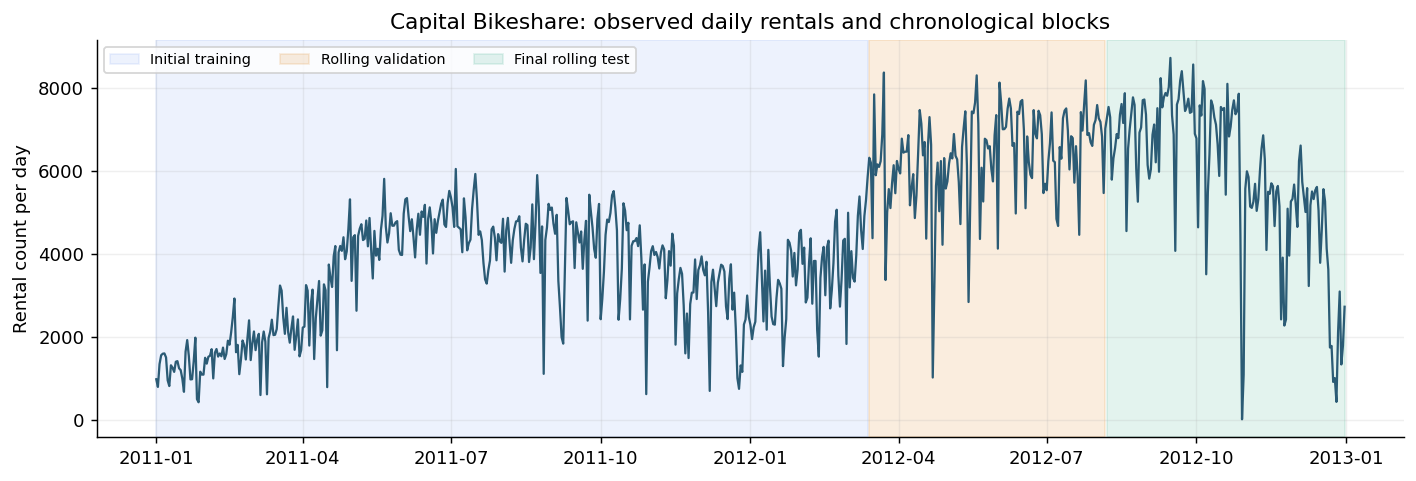

02_diagnostics.png


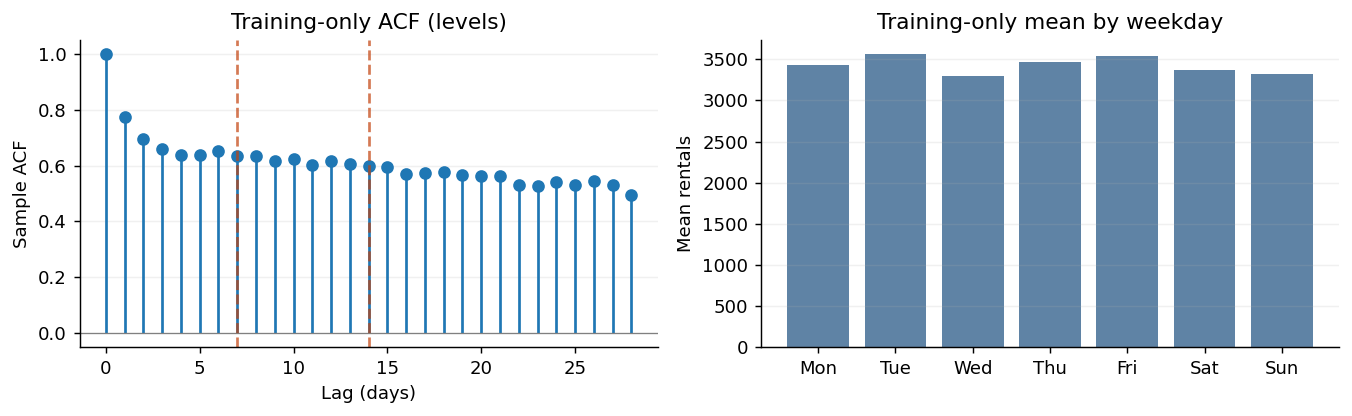

03_comparison.png


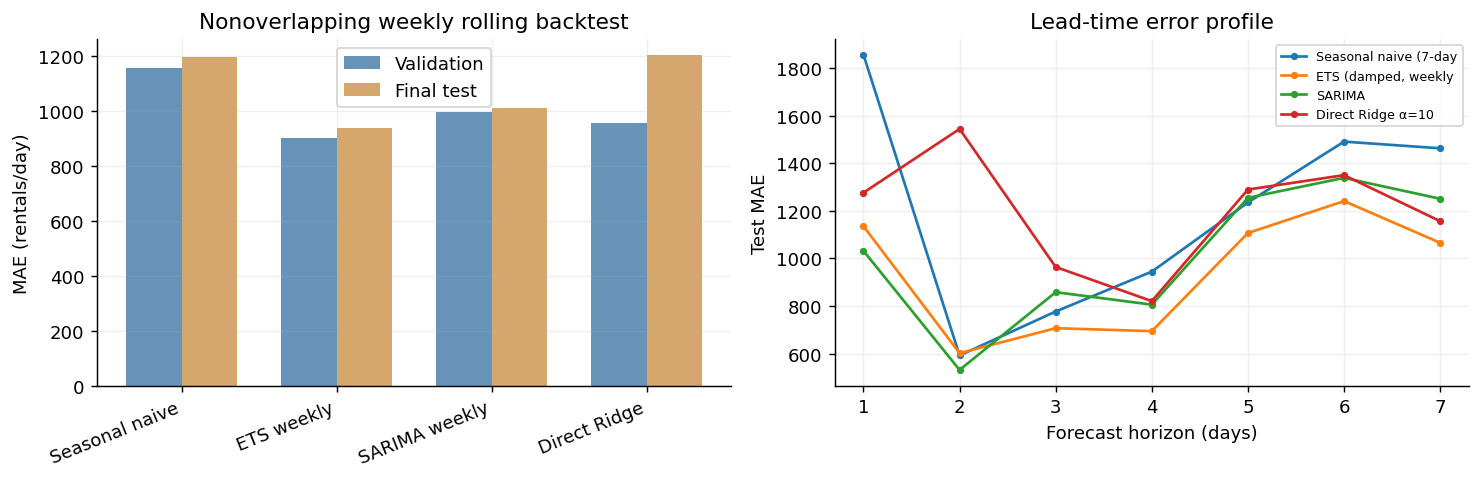

04_test_forecasts.png


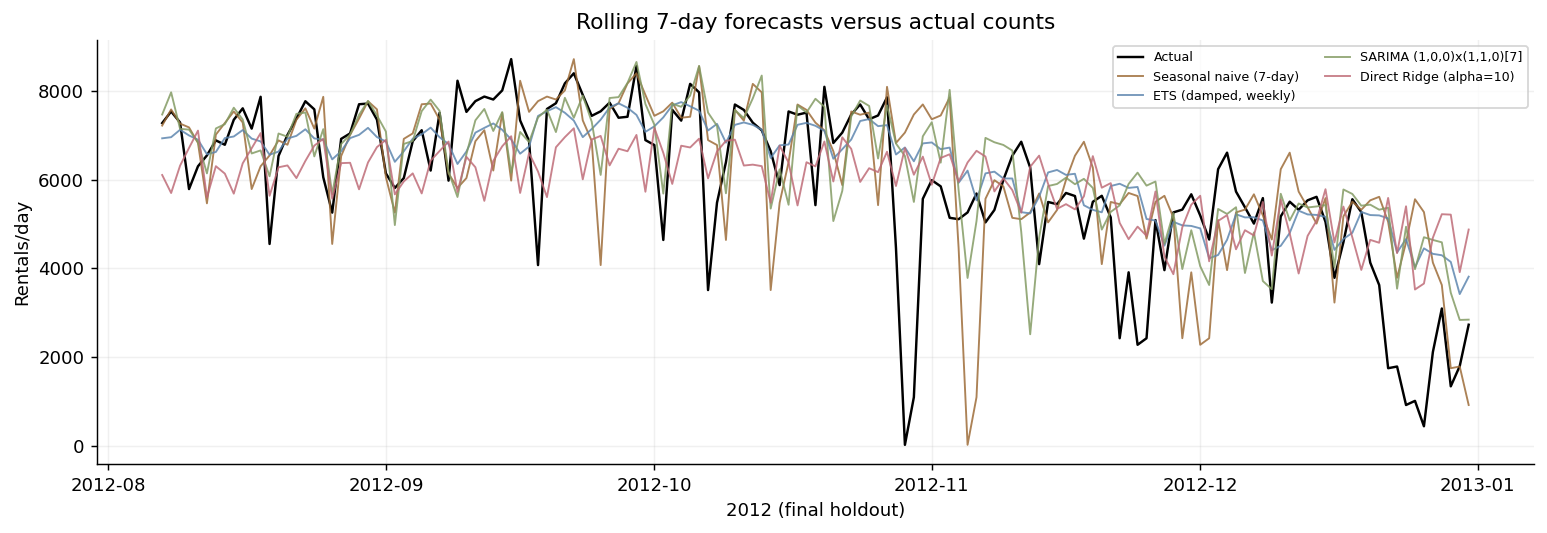

05_test_intervals.png


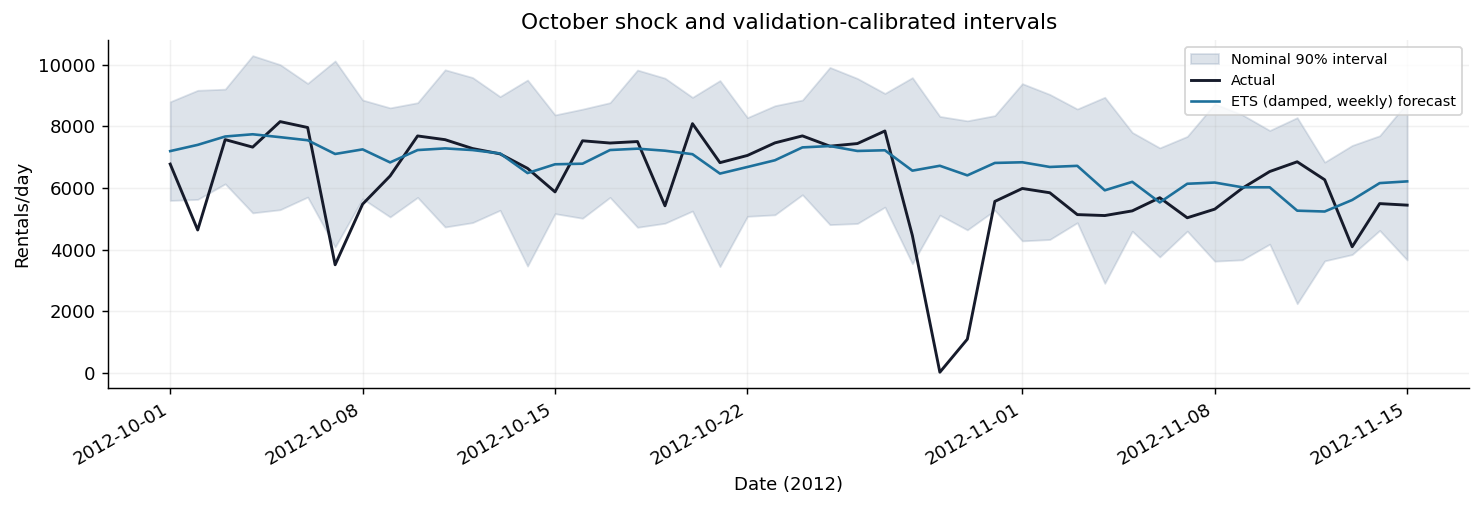

06_error_analysis.png


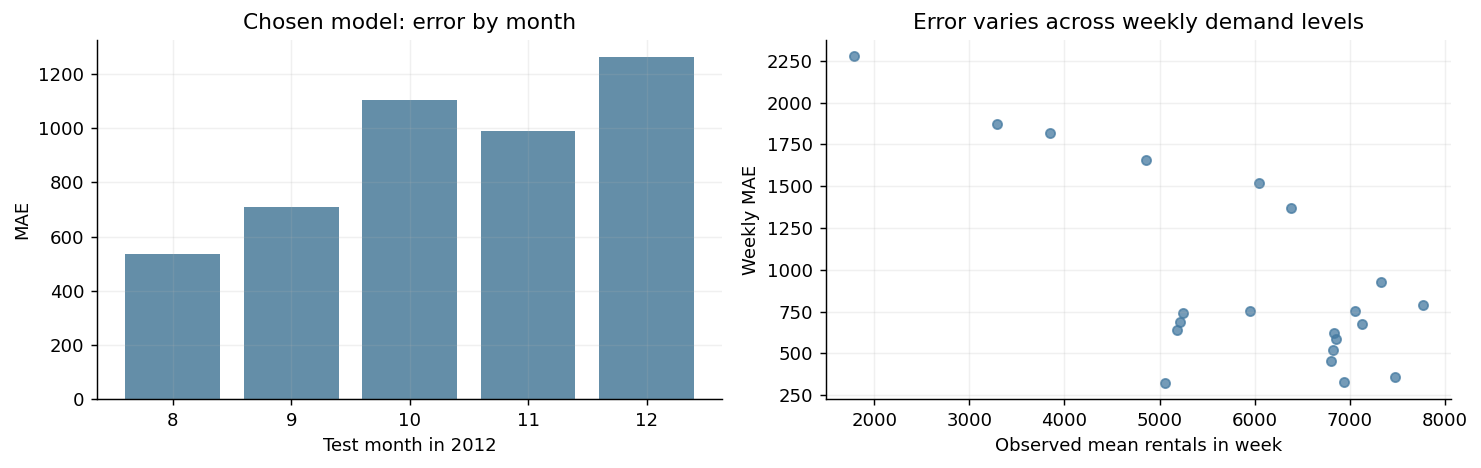

In [30]:
# Plots: clean print and PDF/HTML compatible visuals.
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':130})
fig,ax=plt.subplots(figsize=(11,3.8))
ax.plot(df.index,df.cnt,color='#2b5b75',lw=1.25)
ax.axvspan(train.index[0],train.index[-1],alpha=.08,color='#2563eb',label='Initial training')
ax.axvspan(validation.index[0],validation.index[-1],alpha=.13,color='#d97706',label='Rolling validation')
ax.axvspan(test.index[0],test.index[-1],alpha=.11,color='#059669',label='Final rolling test')
ax.set(ylabel='Rental count per day',title='Capital Bikeshare: observed daily rentals and chronological blocks')
ax.grid(alpha=.2);ax.legend(loc='upper left',ncols=3,fontsize=8)
fig.tight_layout();fig.savefig(ASSETS/'01_series_splits.png',bbox_inches='tight');plt.close(fig)

fig,axs=plt.subplots(1,2,figsize=(10.5,3.3))
lagacf=acf(train.cnt,nlags=28,fft=True)
axs[0].stem(range(len(lagacf)),lagacf,basefmt=' ')
axs[0].axhline(0,color='gray',lw=.7);axs[0].axvline(7,color='#c2410c',ls='--',alpha=.7)
axs[0].axvline(14,color='#c2410c',ls='--',alpha=.7)
axs[0].set(xlabel='Lag (days)',ylabel='Sample ACF',title='Training-only ACF (levels)')
weekday=train.groupby(train.index.dayofweek)['cnt'].mean()
axs[1].bar(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'],weekday.reindex([0,1,2,3,4,5,6]).values,color='#5f83a5')
axs[1].set(ylabel='Mean rentals',title='Training-only mean by weekday')
for a in axs:a.grid(axis='y',alpha=.18)
fig.tight_layout();fig.savefig(ASSETS/'02_diagnostics.png',bbox_inches='tight');plt.close(fig)

fig,axs=plt.subplots(1,2,figsize=(11.5,3.8))
bar_x=np.arange(len(test_model_names))
val_chosen=val_metrics.loc[test_model_names,'MAE']
test_chosen=test_metrics.loc[test_model_names,'MAE']
axs[0].bar(bar_x-.18,val_chosen,width=.36,label='Validation',color='#6793b9')
axs[0].bar(bar_x+.18,test_chosen,width=.36,label='Final test',color='#d5a76c')
axs[0].set_xticks(bar_x)
axs[0].set_xticklabels(['Seasonal naive','ETS weekly','SARIMA weekly','Direct Ridge'],rotation=22,ha='right')
axs[0].set(ylabel='MAE (rentals/day)',title='Nonoverlapping weekly rolling backtest')
axs[0].legend()
for name in test_model_names:
    axs[1].plot(horizon_by_model.columns,horizon_by_model.loc[name],marker='o',ms=3,label=name.replace(' (1,0,0)x(1,1,0)[7]','').replace(' (alpha=',' α=').replace(')',''))
axs[1].set(xlabel='Forecast horizon (days)',ylabel='Test MAE',title='Lead-time error profile')
axs[1].legend(fontsize=7)
for a in axs:a.grid(alpha=.2)
fig.tight_layout();fig.savefig(ASSETS/'03_comparison.png',bbox_inches='tight');plt.close(fig)

fig,ax=plt.subplots(figsize=(12,4.2))
dates=sorted(test_rows.date.unique())
ax.plot(dates,df.loc[dates,'cnt'].values,'k-',lw=1.35,label='Actual')
palette=['#9c6a36','#5c85ae','#829a62','#be6a76']
for name,c in zip(test_model_names,palette):
    r=test_rows[test_rows.model==name].sort_values('date')
    ax.plot(r.date,r.forecast,alpha=.84,lw=1.05,label=name,color=c)
ax.set(xlabel='2012 (final holdout)',ylabel='Rentals/day',title='Rolling 7-day forecasts versus actual counts')
ax.legend(fontsize=7,ncol=2);ax.grid(alpha=.18)
fig.tight_layout();fig.savefig(ASSETS/'04_test_forecasts.png',bbox_inches='tight');plt.close(fig)

fig,ax=plt.subplots(figsize=(11.5,4))
sl=chosen_test.loc[(chosen_test.date>='2012-10-01')&(chosen_test.date<='2012-11-15')].sort_values('date')
ax.fill_between(sl.date,sl.lower90,sl.upper90,alpha=.23,color='#6d86a5',label='Nominal 90% interval')
ax.plot(sl.date,sl.actual,color='#161b2b',lw=1.6,label='Actual')
ax.plot(sl.date,sl.forecast,color='#1d709b',lw=1.45,label=chosen+' forecast')
ax.set(xlabel='Date (2012)',ylabel='Rentals/day',title='October shock and validation-calibrated intervals')
ax.legend(fontsize=8);ax.grid(alpha=.17)
fig.autofmt_xdate();fig.tight_layout()
fig.savefig(Path("capstone_stage1_assets")/'05_test_intervals.png',bbox_inches='tight');plt.close(fig)

fig,axs=plt.subplots(1,2,figsize=(11.5,3.7))
month_mae=model_test.groupby('month').abs_error.mean()
axs[0].bar([str(i) for i in month_mae.index],month_mae.values,color='#648ea8')
axs[0].set(xlabel='Test month in 2012',ylabel='MAE',title='Chosen model: error by month')
axs[1].scatter(weekly.weekly_actual_mean,weekly.week_MAE,s=26,color='#457aa1',alpha=.75)
axs[1].set(xlabel='Observed mean rentals in week',ylabel='Weekly MAE',title='Error varies across weekly demand levels')
for a in axs:a.grid(alpha=.18)
fig.tight_layout();fig.savefig(ASSETS/'06_error_analysis.png',bbox_inches='tight');plt.close(fig)

from IPython.display import Image, display
for figure in sorted(Path("capstone_stage1_assets").glob('*.png')):
    print(figure.name)
    display(Image(filename=str(figure)))

**06_error_analysis.png**

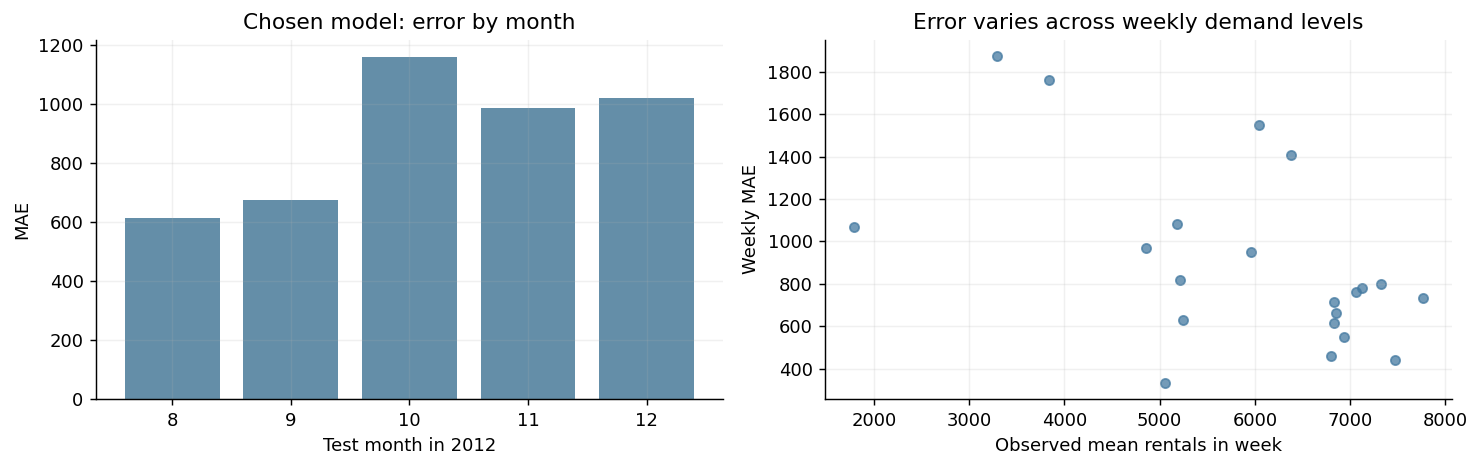

## 8. Export outputs


In [31]:
# Save raw forecast records for independent audit/reproduction.
test_rows.to_csv('capstone_stage1_test_predictions.csv',index=False)
val_rows.to_csv('capstone_stage1_validation_predictions.csv',index=False)
chosen_test.to_csv('capstone_stage1_intervals.csv',index=False)
val_metrics.round(5).to_csv('capstone_stage1_validation_metrics.csv')
test_metrics.round(5).to_csv('capstone_stage1_test_metrics.csv')

def to_native(v):
    if isinstance(v,(np.integer,np.floating)):return v.item()
    if isinstance(v,dict):return {str(k):to_native(x) for k,x in v.items()}
    if isinstance(v,(list,tuple)):return [to_native(x) for x in v]
    return v
summary={
    'title':'Capital Bikeshare 7-day demand forecasts',
    'data': {'rows':n,'target':'cnt','initial_train_n':n_train,'validation_n':n_val,
             'test_n':len(test),'train_start':str(train.index[0].date()),
             'train_end':str(train.index[-1].date()),'val_start':str(validation.index[0].date()),
             'val_end':str(validation.index[-1].date()),'test_start':str(test.index[0].date()),
             'test_end':str(test.index[-1].date()),'dataset_sha256':df.attrs['capstone']['sha256'],
             'source_page':df.attrs['capstone']['source_page'],
             'support_preparation':df.attrs['capstone']['preparation']},
    'selected_ridge':best_alpha,'selected_model':chosen,
    'val_origins_n':len(val_origins),'test_origins_n':len(test_origins),
    'scored_validation_days_per_model':H*len(val_origins),
    'scored_test_days_per_model':H*len(test_origins),
    'validation_first_origin':str(df.index[val_origins[0]].date()),
    'validation_last_origin':str(df.index[val_origins[-1]].date()),
    'test_first_origin':str(df.index[test_origins[0]].date()),
    'test_last_origin':str(df.index[test_origins[-1]].date()),
    'val_metrics':val_metrics.to_dict('index'),'test_metrics':test_metrics.to_dict('index'),
    'test_models':test_model_names,'interval':interval_summary,
    'diagnostics':diagnostics,'subgroups':subgroups,'robustness':robust,
    'worst_days':[{'date':str(r.date.date()),'horizon':int(r.horizon),
                   'actual':int(r.actual),'predicted':round(r.forecast,1),
                   'abs_error':round(r.abs_error,1)} for r in worst.itertuples(index=False)],
    'test_horizon_MAE':horizon_by_model.to_dict('index'),
}
('capstone_stage1_results.json').write_text(json.dumps(to_native(summary),indent=2))

print('Saved:', len(val_rows), 'validation forecast rows;',len(test_rows),'test forecast rows')
print('Selected model:',summary['selected_model'])
print('Final test MAE:',round(test_metrics.loc[chosen,'MAE'],2))

AttributeError: 'str' object has no attribute 'write_text'